In [1]:
import pandas as pd

df = pd.read_excel("CYP2C19_frequency_table.xlsx",
                   sheet_name="Allele frequency",
                   header=1, index_col=0)
df.head(10)

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,African American/Afro-Caribbean,American,Central/South Asian,East Asian,European,Latino,Near Eastern,Oceanian,Sub-Saharan African
CYP2C19 allele,,,,,,,,,
*1,0.546762,0.792184,0.543626,0.595549,0.625141,0.716553,0.672251,0.187099,0.551507
*2,0.181495,0.121365,0.269916,0.283523,0.146857,0.104187,0.119847,0.609520,0.156843
*3,0.002757,0.000352,0.015685,0.072473,0.001618,0.000828,0.016479,0.146381,0.002668
*4,0.000000,0.000019,0.000000,0.000177,0.002360,0.000520,0.000000,NaN,0.000000
*5,0.000000,0.000000,0.000000,0.003225,0.000029,0.000000,0.000000,NaN,0.000000
*6,0.000000,NaN,0.000000,0.000560,0.000300,0.000000,0.000000,NaN,0.000000
*7,0.000000,NaN,0.000000,0.000114,0.000000,0.000000,NaN,NaN,0.000000
*8,0.001120,0.000000,0.000000,0.000000,0.003359,0.001274,0.000000,NaN,0.000000
*9,0.014347,NaN,NaN,0.000115,0.000660,0.000839,NaN,NaN,0.026962


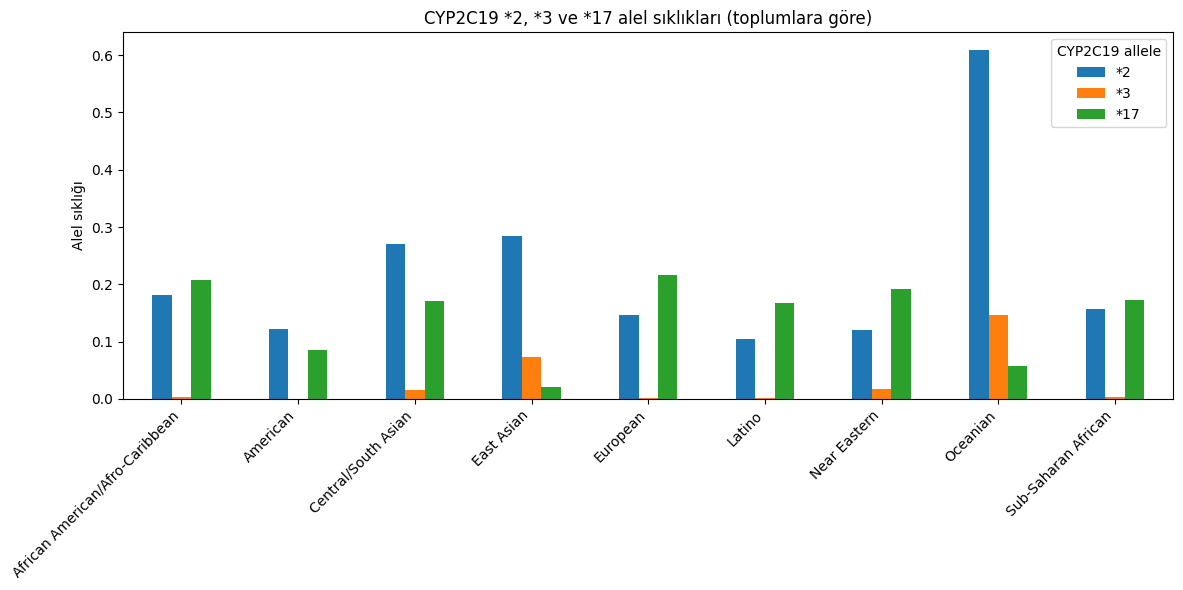

In [2]:
import matplotlib.pyplot as plt

secilen = df.loc[["*2", "*3", "*17"]]

secilen.T.plot(kind="bar", figsize=(12, 6))
plt.ylabel("Alel sıklığı")
plt.title("CYP2C19 *2, *3 ve *17 alel sıklıkları (toplumlara göre)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

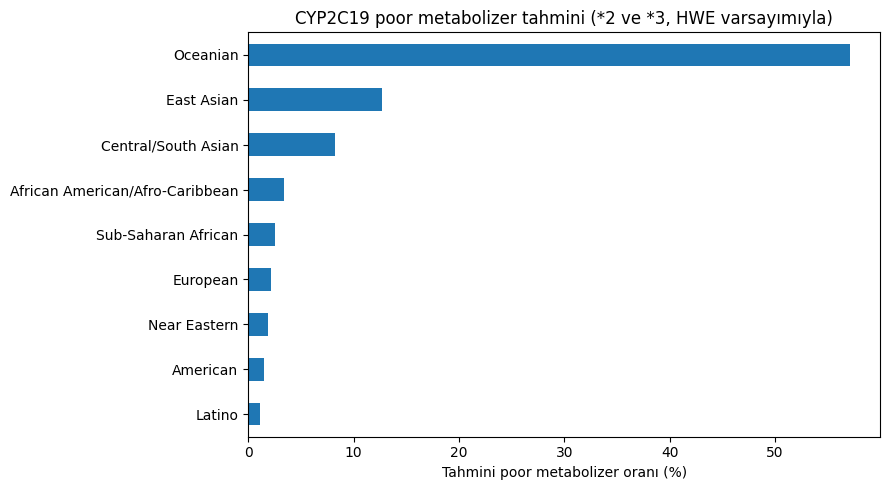

Oceanian                           57.1
East Asian                         12.7
Central/South Asian                 8.2
African American/Afro-Caribbean     3.4
Sub-Saharan African                 2.5
European                            2.2
Near Eastern                        1.9
American                            1.5
Latino                              1.1
dtype: float64


In [3]:
nofunc = df.loc["*2"] + df.loc["*3"]
pm = (nofunc ** 2 * 100).round(1)

pm.sort_values().plot(kind="barh", figsize=(9, 5))
plt.xlabel("Tahmini poor metabolizer oranı (%)")
plt.title("CYP2C19 poor metabolizer tahmini (*2 ve *3, HWE varsayımıyla)")
plt.tight_layout()
plt.show()

print(pm.sort_values(ascending=False))

In [4]:
ph = pd.read_excel("CYP2C19_frequency_table.xlsx",
                   sheet_name="Phenotype frequency",
                   header=None)
ph.head(15)

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1,2,3,4,5,6,7,8,9
0,Frequencies of CYP2C19 phenotypes in biogeogra...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Phenotype,African American/Afro-Caribbean,American,Central/South Asian,East Asian,European,Latino,Near Eastern,Oceanian,Sub-Saharan African
2,Ultrarapid Metabolizer,0.042943195,0.0074097984,0.029163336,0.00042194634,0.04641379,0.02774172,0.036642652,0.003249,0.030045323
3,Rapid Metabolizer,0.2373838,0.13638271,0.18567303,0.025343522,0.2711846,0.24136075,0.2573682,0.021329276,0.21080859
4,Poor Metabolizer,0.040512204,0.014819587,0.08156806,0.12978691,0.02387743,0.011408395,0.018584846,0.5713864,0.036714304
5,Normal Metabolizer,0.32805592,0.62755567,0.29552925,0.38055435,0.39611652,0.5249766,0.45192146,0.035006005,0.36977687
6,Likely Poor Metabolizer,0.007090685,0.0,0.0,0.0004349198,0.00020405183,0.0004440685,0.0,0.0,0.010332189
7,Likely Intermediate Metabolizer,0.027788177,0.0,0.0,0.00076989824,0.0011160374,0.003709162,0.0,0.0,0.042863965
8,Intermediate Metabolizer,0.31398684,0.21383229,0.40806636,0.45928204,0.26108757,0.19035932,0.2354828,0.36902928,0.29945874
9,Indeterminate,0.0022393465,0.0,0.0,0.0034064606,0.0,0.0,0.0,0.0,0.0


                                 Bizim (HWE)  CPIC  Fark
Oceanian                                57.1  57.1   0.0
East Asian                              12.7  13.0  -0.3
Central/South Asian                      8.2   8.2   0.0
African American/Afro-Caribbean          3.4   4.1  -0.7
Sub-Saharan African                      2.5   3.7  -1.2
European                                 2.2   2.4  -0.2
Near Eastern                             1.9   1.9   0.0
American                                 1.5   1.5   0.0
Latino                                   1.1   1.1   0.0


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


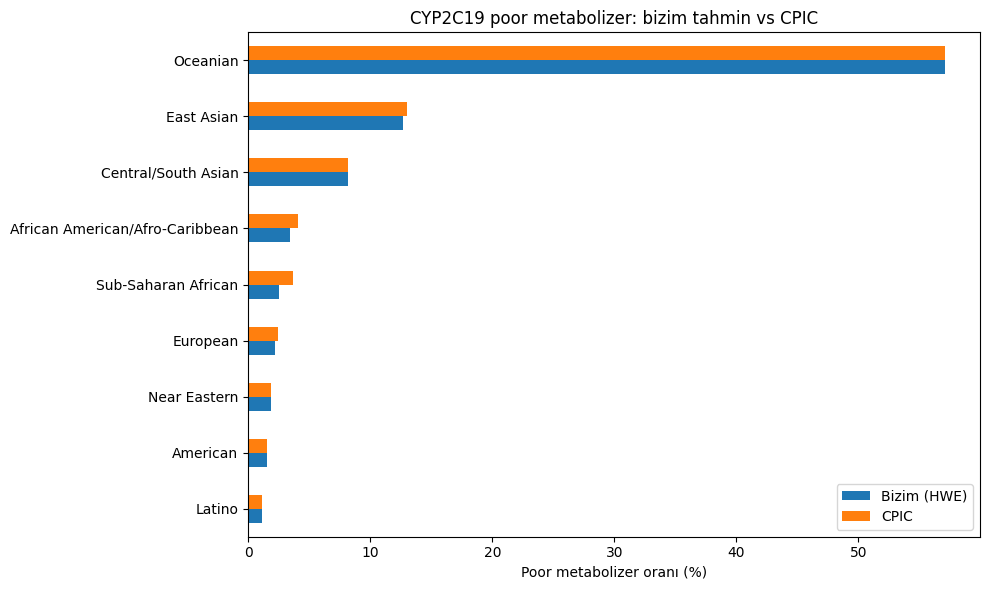

In [5]:
ph = pd.read_excel("CYP2C19_frequency_table.xlsx",
                   sheet_name="Phenotype frequency",
                   header=1, index_col=0)

cpic = pd.to_numeric(ph.loc["Poor Metabolizer"], errors="coerce") * 100

kars = pd.DataFrame({"Bizim (HWE)": pm, "CPIC": cpic.round(1)})
kars["Fark"] = (kars["Bizim (HWE)"] - kars["CPIC"]).round(1)
print(kars.sort_values("CPIC", ascending=False))

kars[["Bizim (HWE)", "CPIC"]].sort_values("CPIC").plot(kind="barh", figsize=(10, 6))
plt.xlabel("Poor metabolizer oranı (%)")
plt.title("CYP2C19 poor metabolizer: bizim tahmin vs CPIC")
plt.tight_layout()
plt.show()

In [6]:
from google.colab import files

# Grafik 1: alel sıklıkları
df.loc[["*2", "*3", "*17"]].T.plot(kind="bar", figsize=(12, 6))
plt.ylabel("Alel sıklığı")
plt.title("CYP2C19 *2, *3 ve *17 alel sıklıkları (toplumlara göre)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("fig1_alel_sikliklari.png", dpi=200)
plt.close()

# Grafik 2: bizim tahmin vs CPIC
kars[["Bizim (HWE)", "CPIC"]].sort_values("CPIC").plot(kind="barh", figsize=(10, 6))
plt.xlabel("Poor metabolizer oranı (%)")
plt.title("CYP2C19 poor metabolizer: bizim tahmin vs CPIC")
plt.tight_layout()
plt.savefig("fig2_pm_karsilastirma.png", dpi=200)
plt.close()

# Karşılaştırma tablosu
kars.to_csv("pm_karsilastirma.csv")

for f in ["fig1_alel_sikliklari.png", "fig2_pm_karsilastirma.png", "pm_karsilastirma.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>